# compare

Six R-GCN runs on the same disease holdout. Compare message normalization, ranking losses, and negative sampling using per-disease retrieval metrics and paired bootstrap intervals.

```
data    primekg 2.1
split   development / 136 diseases / 7,957 drugs
runs    6 / 120 epochs / seed 101
source  cda583e5a903
```

In [1]:
BUCKET = "hf://buckets/exapt-lab/hangar/runs"

RUNS = (
    "rgcn-lsep-total-n08",
    "rgcn-lsep-relation-n08",
    "rgcn-lsep-relation-n32",
    "rgcn-lsep-relation-n64",
    "rgcn-bce-relation-n32",
    "rgcn-bpr-relation-n32",
)

BOOTSTRAP_SEED = 163
BOOTSTRAP_SAMPLES = 20_000

In [2]:
import csv
import json
import shutil
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files, userdata

subprocess.run(
    [sys.executable, "-m", "pip", "install", "--quiet", "huggingface_hub>=2.3,<3"],
    check=True,
)
from huggingface_hub import sync_bucket

ROOT = Path("/content/exapt-compare")
DATA = ROOT / "runs"
OUT = ROOT / "out"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

token = userdata.get("exapt_hf")
if not token:
    raise RuntimeError("missing Colab secret: exapt_hf")

for run in RUNS:
    sync_bucket(
        f"{BUCKET}/{run}", str(DATA / run),
        include=["*.json", "*.jsonl"], token=token, quiet=True,
    )
    print(f"source   {run}")

source   rgcn-lsep-total-n08
source   rgcn-lsep-relation-n08
source   rgcn-lsep-relation-n32
source   rgcn-lsep-relation-n64
source   rgcn-bce-relation-n32
source   rgcn-bpr-relation-n32


In [3]:
def read_json(path):
    return json.loads(path.read_text())


def write_csv(name, rows):
    with (OUT / name).open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=rows[0])
        writer.writeheader()
        writer.writerows(rows)


runs = {}
for run in RUNS:
    path = DATA / run
    epochs = [json.loads(line) for line in (path / "epochs.jsonl").read_text().splitlines()]
    runs[run] = {
        "config": read_json(path / "config.json"),
        "benchmark": read_json(path / "benchmark.json"),
        "development": read_json(path / "development.json"),
        "epochs": epochs,
        "best": max(epochs, key=lambda e: (e["development_recall"], e["development_ndcg"])),
    }

if len({r["benchmark"]["sha256"] for r in runs.values()}) != 1:
    raise ValueError("benchmark mismatch")

DISEASES = runs[RUNS[0]]["benchmark"]["development"]
by_disease = {
    run: {d["disease"]: d for d in data["development"]["per_disease"]}
    for run, data in runs.items()
}
print(f"loaded   {len(runs)} runs / {len(DISEASES)} diseases")

loaded   6 runs / 136 diseases


In [4]:
summary, histories, per_disease = [], [], []
for run, data in runs.items():
    selected = data["development"]
    final = data["epochs"][-1]
    summary.append({
        "run": run,
        "selected_epoch": data["best"]["epoch"],
        "selected_recall20": selected["recall"],
        "selected_ndcg20": selected["ndcg"],
        "final_recall20": final["development_recall"],
        "final_ndcg20": final["development_ndcg"],
    })
    histories.extend({"run": run, **epoch} for epoch in data["epochs"])
    per_disease.extend({
        "run": run,
        "disease": d["disease"],
        "positives": d["positives"],
        "recall20": d["recall"],
        "ndcg20": d["ndcg"],
        "reciprocal_rank": d["reciprocal_rank"],
    } for d in selected["per_disease"])

write_csv("runs.csv", summary)
write_csv("epochs.csv", histories)
write_csv("diseases.csv", per_disease)

for row in sorted(summary, key=lambda r: -r["selected_recall20"]):
    print(
        f'{row["run"]:28}  e{row["selected_epoch"]:04d}'
        f'  {row["selected_recall20"]:.4f}  {row["selected_ndcg20"]:.4f}'
    )

rgcn-lsep-relation-n64        e0083  0.4832  0.4170
rgcn-lsep-relation-n32        e0077  0.4818  0.4053
rgcn-bce-relation-n32         e0109  0.4507  0.3997
rgcn-lsep-relation-n08        e0120  0.4390  0.3537
rgcn-bpr-relation-n32         e0114  0.4076  0.3349
rgcn-lsep-total-n08           e0120  0.2948  0.1959


In [5]:
CONTRASTS = (
    ("Rel n08 - Total n08", RUNS[0], RUNS[1]),
    ("LSEP n32 - LSEP n08", RUNS[1], RUNS[2]),
    ("LSEP n64 - LSEP n32", RUNS[2], RUNS[3]),
    ("LSEP n32 - BCE n32", RUNS[4], RUNS[2]),
    ("LSEP n32 - BPR n32", RUNS[5], RUNS[2]),
)

indices = np.random.default_rng(BOOTSTRAP_SEED).integers(
    len(DISEASES), size=(BOOTSTRAP_SAMPLES, len(DISEASES))
)
contrasts = []
for label, control, treatment in CONTRASTS:
    for metric in ("recall", "ndcg"):
        delta = np.array([
            by_disease[treatment][d][metric] - by_disease[control][d][metric]
            for d in DISEASES
        ])
        lower, upper = np.quantile(delta[indices].mean(axis=1), (0.025, 0.975))
        contrasts.append({
            "comparison": label,
            "control": control,
            "treatment": treatment,
            "metric": f"{metric}@20",
            "n": len(delta),
            "difference": delta.mean(),
            "lower95": lower,
            "upper95": upper,
            "improved": int((delta > 0).sum()),
            "tied": int((delta == 0).sum()),
            "declined": int((delta < 0).sum()),
            "bootstrap_seed": BOOTSTRAP_SEED,
            "bootstrap_samples": BOOTSTRAP_SAMPLES,
        })

write_csv("contrasts.csv", contrasts)
for row in contrasts:
    if row["metric"] == "recall@20":
        print(
            f'{row["comparison"]:25} {row["difference"]:+.4f}'
            f'  [{row["lower95"]:+.4f}, {row["upper95"]:+.4f}]'
        )

Rel n08 - Total n08       +0.1442  [+0.0861, +0.2039]
LSEP n32 - LSEP n08       +0.0428  [-0.0013, +0.0881]
LSEP n64 - LSEP n32       +0.0015  [-0.0293, +0.0328]
LSEP n32 - BCE n32        +0.0311  [-0.0109, +0.0742]
LSEP n32 - BPR n32        +0.0742  [+0.0249, +0.1249]


In [6]:
from matplotlib import font_manager

FONT_DIR = ROOT / "fonts"
FONT_DIR.mkdir(exist_ok=True)

FONTS = {
    "SourceSans3-Medium.ttf": "https://raw.githubusercontent.com/adobe-fonts/source-sans/release/TTF/SourceSans3-Medium.ttf",
    "SourceSans3-Semibold.ttf": "https://raw.githubusercontent.com/adobe-fonts/source-sans/release/TTF/SourceSans3-Semibold.ttf",
    "UbuntuMono-Regular.ttf": "https://raw.githubusercontent.com/google/fonts/main/ufl/ubuntumono/UbuntuMono-Regular.ttf",
}

for filename, url in FONTS.items():
    path = FONT_DIR / filename
    if not path.exists():
        urlretrieve(url, path)
    font_manager.fontManager.addfont(path)

SANS = font_manager.FontProperties(fname=FONT_DIR / "SourceSans3-Medium.ttf").get_name()
MONO = font_manager.FontProperties(fname=FONT_DIR / "UbuntuMono-Regular.ttf").get_name()

P = {
    "panel": "#202020", "grid": "#404040",
    "fg": "#e4e4ef", "muted": "#a0a0a0",
    "cyan": "#89a6a5", "orange": "#b69971",
    "pink": "#b491b3", "blue": "#8a98ac",
}

mpl.rcParams.update({
    "font.family": SANS,
    "font.weight": "medium",
    "font.size": 18,
    "axes.labelsize": 20,
    "axes.labelweight": "semibold",
    "axes.labelpad": 20,
    "xtick.labelsize": 17,
    "ytick.labelsize": 17,
    "legend.fontsize": 17,
    "figure.facecolor": P["panel"],
    "axes.facecolor": P["panel"],
    "savefig.facecolor": P["panel"],
    "text.color": P["fg"],
    "axes.labelcolor": P["fg"],
    "axes.edgecolor": P["grid"],
    "xtick.color": P["muted"],
    "ytick.color": P["muted"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "grid.color": P["grid"],
    "grid.alpha": 0.65,
    "svg.fonttype": "path",
    "pdf.fonttype": 42,
})

LABELS = {
    RUNS[0]: "LSEP / total / n08",
    RUNS[1]: "LSEP / relation / n08",
    RUNS[2]: "LSEP / relation / n32",
    RUNS[3]: "LSEP / relation / n64",
    RUNS[4]: "BCE / relation / n32",
    RUNS[5]: "BPR / relation / n32",
}
COLORS = {
    RUNS[0]: P["orange"],
    RUNS[1]: P["cyan"],
    RUNS[2]: P["pink"], RUNS[3]: P["pink"],
    RUNS[4]: P["blue"], RUNS[5]: P["blue"],
}


def save(fig, name):
    for ext in ("svg", "pdf", "png"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=300,
                    bbox_inches="tight", pad_inches=0.25)
    plt.show()
    plt.close(fig)


print(f"font     {SANS} / {MONO}")

font     Source Sans 3 / Ubuntu Mono


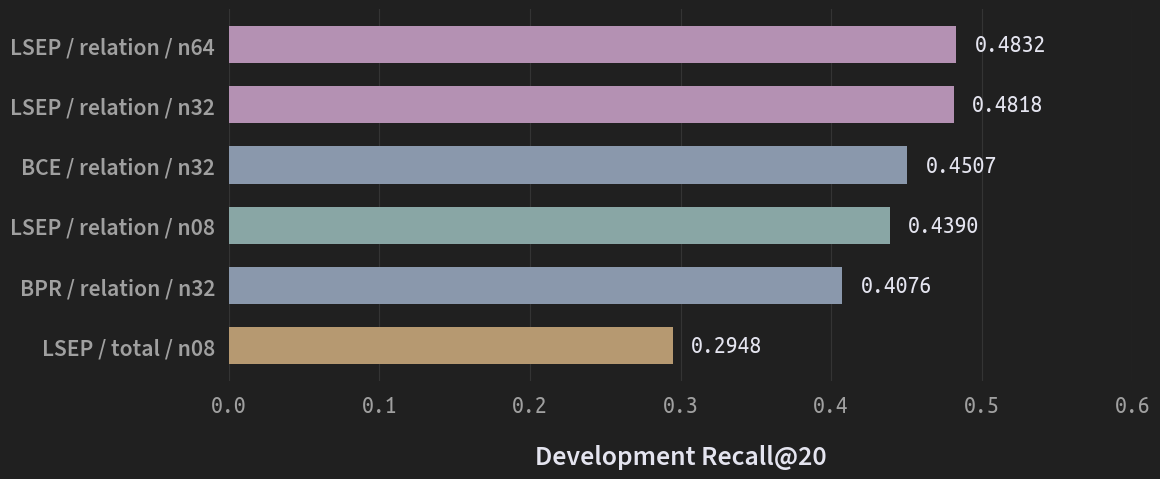

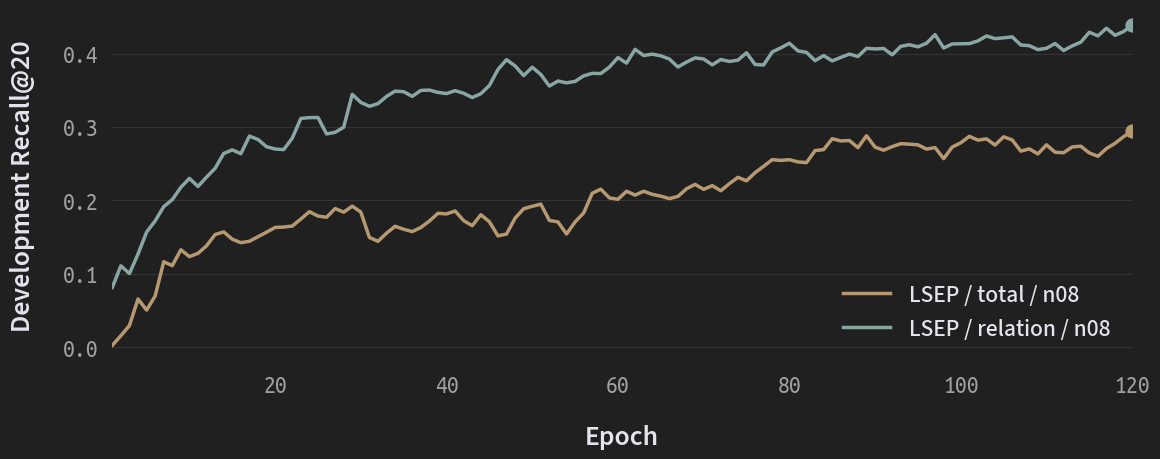

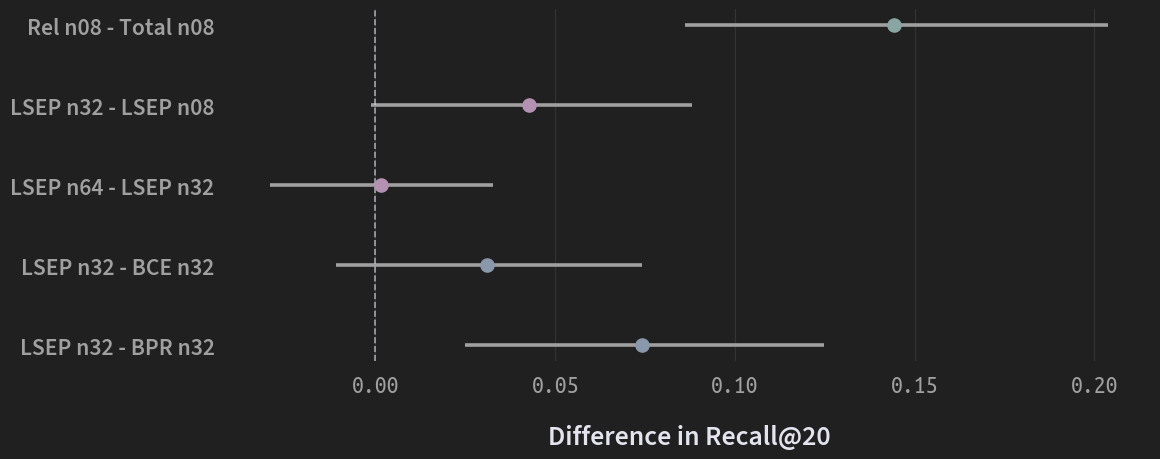

In [7]:
ordered = sorted(summary, key=lambda r: r["selected_recall20"])
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.barh(
    range(len(ordered)), [r["selected_recall20"] for r in ordered],
    color=[COLORS[r["run"]] for r in ordered], height=0.62,
)
ax.set_yticks(range(len(ordered)), [LABELS[r["run"]] for r in ordered], fontweight="semibold")
ax.set(xlim=(0, 0.60), xlabel="Development Recall@20")
ax.set_xticks(np.arange(0, 0.61, 0.1))
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=10)
plt.setp(ax.get_xticklabels(), fontfamily=MONO)
for i, row in enumerate(ordered):
    ax.text(row["selected_recall20"] + 0.012, i,
            f'{row["selected_recall20"]:.4f}', va="center", fontfamily=MONO, fontsize=17)
fig.tight_layout(pad=1.2)
save(fig, "scores")

fig, ax = plt.subplots(figsize=(12, 5.0))
for run in (RUNS[0], RUNS[1]):
    history = runs[run]["epochs"]
    ax.plot(
        [e["epoch"] for e in history],
        [e["development_recall"] for e in history],
        color=COLORS[run], linewidth=2.5, label=LABELS[run],
    )
    best = runs[run]["best"]
    ax.scatter(best["epoch"], best["development_recall"],
               color=COLORS[run], s=85, zorder=3)
ax.set(xlim=(1, 120), xlabel="Epoch", ylabel="Development Recall@20")
ax.legend(frameon=False, loc="lower right", labelcolor=P["fg"])
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=10)
plt.setp(ax.get_xticklabels() + ax.get_yticklabels(), fontfamily=MONO)
fig.tight_layout(pad=1.2)
save(fig, "normalization")

paired = [r for r in contrasts if r["metric"] == "recall@20"]
fig, ax = plt.subplots(figsize=(12, 5.0))
for i, row in enumerate(paired):
    ax.hlines(i, row["lower95"], row["upper95"], color=P["muted"], linewidth=2.6)
    ax.scatter(row["difference"], i, color=P["cyan"] if i == 0 else P["pink"] if i < 3 else P["blue"],
               s=90, zorder=3)
ax.axvline(0, color=P["fg"], alpha=0.65, linestyle="--", linewidth=1.2)
ax.set_yticks(range(len(paired)), [r["comparison"] for r in paired], fontweight="semibold")
ax.invert_yaxis()
ax.set(xlabel="Difference in Recall@20")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=10)
plt.setp(ax.get_xticklabels(), fontfamily=MONO)
fig.tight_layout(pad=1.2)
save(fig, "contrasts")

In [8]:
archive = shutil.make_archive(str(ROOT), "zip", root_dir=OUT)
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>